# CMSC5702 Assignment 1 Teacher Benchmark Analysis

## Sequential, OpenMP, and MPI implementation comparisons

This notebook reads `Time Measurements.xlsx`, summarizes five-run timing measurements, and compares two OpenMP implementations and three MPI implementations. All speedup and efficiency values use the updated sequential implementation in the `Sequential` worksheet as the common baseline $T(n,1)$.


## Implementation variants

- `OpenMP1`: `schedule(static)` with `reduction(max:diff)`.
- `OpenMP2`: `schedule(static)` with `reduction(max:diff)` and `collapse(2)`.
- `MPI1`: sub-optimal chain-like ordering of processes with less communication concurrency.
- `MPI2`: blocking `MPI_Sendrecv`, with more communication concurrency than MPI1.
- `MPI3`: nonblocking communication.

The parallel worksheets include `p=1` measurements. These are useful for observing parallel-code overhead, but they are not used as the speedup baseline.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

RUN_COLUMNS = [f"runtime{i}" for i in range(1, 6)]
N_VALUES = [200, 300, 400]

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")


INPUT_FILE = Path("Time Measurements.xlsx")
PROCESSOR_VALUES = [1, 2, 4, 8, 16, 32]
VERSION_DESCRIPTIONS = {
    "OpenMP1": "schedule(static), reduction(max:diff)",
    "OpenMP2": "schedule(static), reduction(max:diff), collapse(2)",
    "MPI1": "chain-like ordering; less communication concurrency",
    "MPI2": "MPI_Sendrecv; blocking; more communication concurrency",
    "MPI3": "nonblocking communication",
}
COLORS = {
    "OpenMP1": "#1f77b4",
    "OpenMP2": "#ff7f0e",
    "MPI1": "#9467bd",
    "MPI2": "#2ca02c",
    "MPI3": "#d62728",
}

if not INPUT_FILE.exists():
    raise FileNotFoundError(f"Input workbook not found: {INPUT_FILE}")


In [2]:
def prepare_table(df, table_name, key_columns):
    result = df.copy()
    result.columns = [str(column).strip().lower() for column in result.columns]
    required = key_columns + RUN_COLUMNS
    missing = [column for column in required if column not in result.columns]
    if missing:
        raise ValueError(
            f"{table_name} is missing required column(s): {', '.join(missing)}"
        )

    result = result[required].copy()
    for column in required:
        result[column] = pd.to_numeric(result[column], errors="coerce")

    if result[key_columns].isna().any(axis=None):
        bad_rows = result.index[result[key_columns].isna().any(axis=1)].tolist()
        raise ValueError(f"{table_name} has missing or invalid keys in row(s): {bad_rows}")
    if result.duplicated(key_columns).any():
        duplicates = result.loc[result.duplicated(key_columns, keep=False), key_columns]
        raise ValueError(
            f"{table_name} has duplicate configurations:\n"
            + duplicates.to_string(index=False)
        )

    for column in key_columns:
        if not np.allclose(result[column], np.round(result[column])):
            raise ValueError(f"{table_name}: {column} must contain whole numbers.")
        result[column] = result[column].astype(int)

    if (result[RUN_COLUMNS] <= 0).any(axis=None):
        raise ValueError(f"{table_name} contains a zero or negative execution time.")

    result["runs_completed"] = result[RUN_COLUMNS].notna().sum(axis=1)
    complete = result["runs_completed"].eq(5)
    result["average_time"] = result[RUN_COLUMNS].mean(axis=1).where(complete)
    result["std_dev"] = result[RUN_COLUMNS].std(axis=1, ddof=1).where(complete)
    result["coefficient_of_variation"] = (
        result["std_dev"] / result["average_time"]
    )
    return result.sort_values(key_columns).reset_index(drop=True)


def add_scaling_metrics(parallel_df, sequential_df, table_name):
    baseline = sequential_df[["n", "average_time"]].rename(
        columns={"average_time": "sequential_time"}
    )
    result = parallel_df.merge(
        baseline, on="n", how="left", validate="many_to_one"
    )
    valid = (
        result["average_time"].gt(0)
        & result["sequential_time"].gt(0)
        & result["p"].gt(0)
    )
    result["speedup"] = np.where(
        valid,
        result["sequential_time"] / result["average_time"],
        np.nan,
    )
    result["efficiency"] = np.where(
        valid,
        result["speedup"] / result["p"],
        np.nan,
    )
    missing_baseline = sorted(
        result.loc[result["sequential_time"].isna(), "n"].unique()
    )
    if missing_baseline:
        warnings.warn(
            f"{table_name}: no complete sequential baseline is available for "
            f"n={missing_baseline}."
        )
    return result


def show_no_data(ax):
    ax.text(
        0.5,
        0.5,
        "Enter all five measurements and rerun the notebook.",
        ha="center",
        va="center",
        transform=ax.transAxes,
    )


def configure_processor_axis(ax, ticks):
    ax.set_xscale("log", base=2)
    ax.set_xticks(ticks)
    ax.get_xaxis().set_major_formatter(ScalarFormatter())
    ax.set_xlabel("Number of processors, p")


In [3]:
required_sheets = ["Sequential", "OpenMP1", "OpenMP2", "MPI1", "MPI2", "MPI3"]
workbook = pd.ExcelFile(INPUT_FILE)
missing_sheets = [name for name in required_sheets if name not in workbook.sheet_names]
if missing_sheets:
    raise ValueError(f"Missing worksheet(s): {missing_sheets}")

seq_df = prepare_table(
    pd.read_excel(INPUT_FILE, sheet_name="Sequential"),
    "Sequential",
    ["n"],
)

results = {}
for version in required_sheets[1:]:
    prepared = prepare_table(
        pd.read_excel(INPUT_FILE, sheet_name=version),
        version,
        ["n", "p"],
    )
    results[version] = add_scaling_metrics(prepared, seq_df, version)

parallel_df = pd.concat(
    [df.assign(version=version) for version, df in results.items()],
    ignore_index=True,
)
parallel_df["family"] = np.where(
    parallel_df["version"].str.startswith("OpenMP"), "OpenMP", "MPI"
)

if parallel_df["average_time"].isna().any() or seq_df["average_time"].isna().any():
    warnings.warn("At least one configuration does not contain all five measurements.")

print(f"Loaded {INPUT_FILE}: {len(seq_df)} sequential rows and {len(parallel_df)} parallel rows.")


Loaded Time Measurements.xlsx: 3 sequential rows and 90 parallel rows.


## Sequential baseline

The `Sequential` worksheet supplies the common $T(n,1)$ baseline used for every speedup and efficiency calculation.

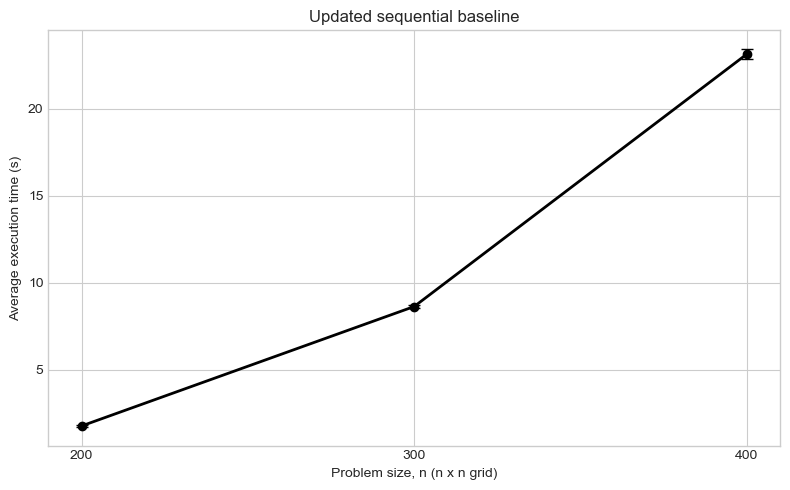

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    seq_df["n"],
    seq_df["average_time"],
    yerr=seq_df["std_dev"],
    marker="o",
    linewidth=2,
    capsize=4,
    color="black",
)
ax.set_title("Updated sequential baseline")
ax.set_xlabel("Problem size, n (n x n grid)")
ax.set_ylabel("Average execution time (s)")
ax.set_xticks(N_VALUES)
fig.tight_layout()
plt.show()


In [5]:
def plot_version_comparison(data, versions, metric, title, ylabel, ideal=None):
    fig, axes = plt.subplots(1, len(N_VALUES), figsize=(17, 4.8), sharey=False)
    for ax, n in zip(axes, N_VALUES):
        for version in versions:
            subset = data[
                (data["version"] == version)
                & (data["n"] == n)
                & data[metric].notna()
            ].sort_values("p")
            if subset.empty:
                continue
            if metric == "average_time":
                ax.errorbar(
                    subset["p"],
                    subset[metric],
                    yerr=subset["std_dev"].fillna(0),
                    marker="o",
                    capsize=3,
                    color=COLORS[version],
                    label=version,
                )
            else:
                ax.plot(
                    subset["p"],
                    subset[metric],
                    marker="o",
                    color=COLORS[version],
                    label=version,
                )

        if ideal == "speedup":
            ax.plot(
                PROCESSOR_VALUES,
                PROCESSOR_VALUES,
                "k--",
                alpha=0.45,
                label="Ideal",
            )
        elif ideal == "efficiency":
            ax.axhline(1.0, color="black", linestyle="--", alpha=0.45, label="Ideal")

        configure_processor_axis(ax, PROCESSOR_VALUES)
        ax.set_title(f"n={n}")
        ax.set_ylabel(ylabel)
        ax.legend()

    fig.suptitle(title, y=1.02, fontsize=14)
    fig.tight_layout()
    plt.show()


## OpenMP plots

The figures compare OpenMP1 and OpenMP2 using average execution time, speedup, and efficiency.

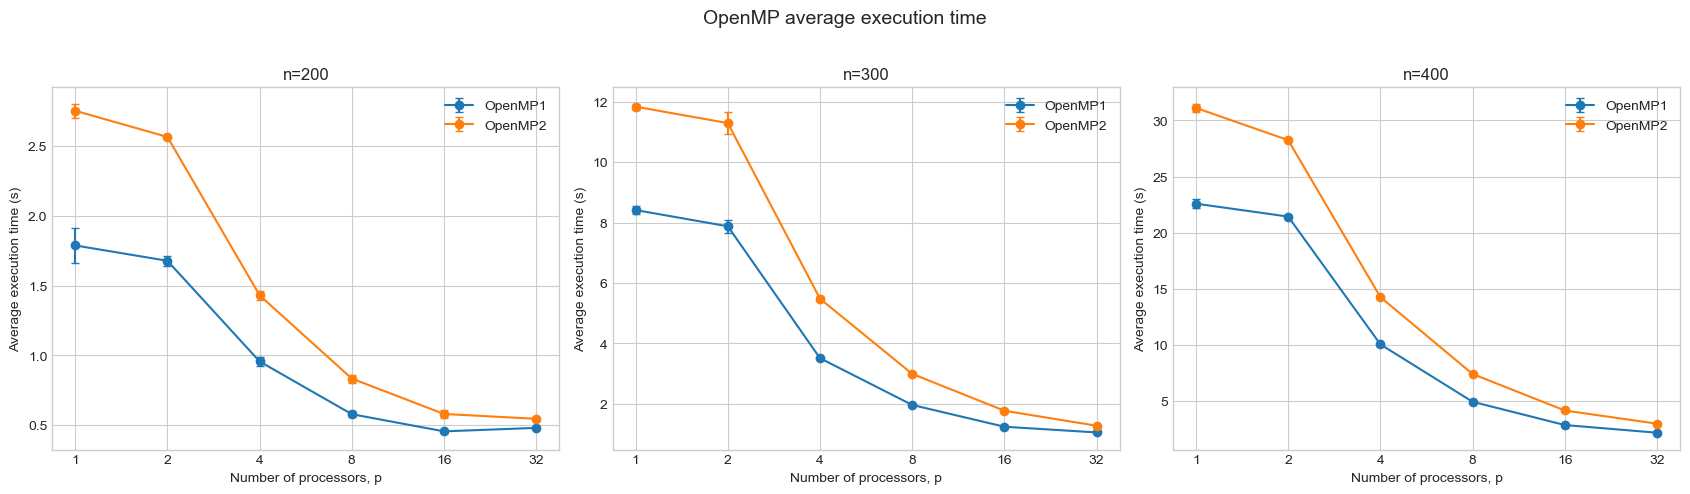

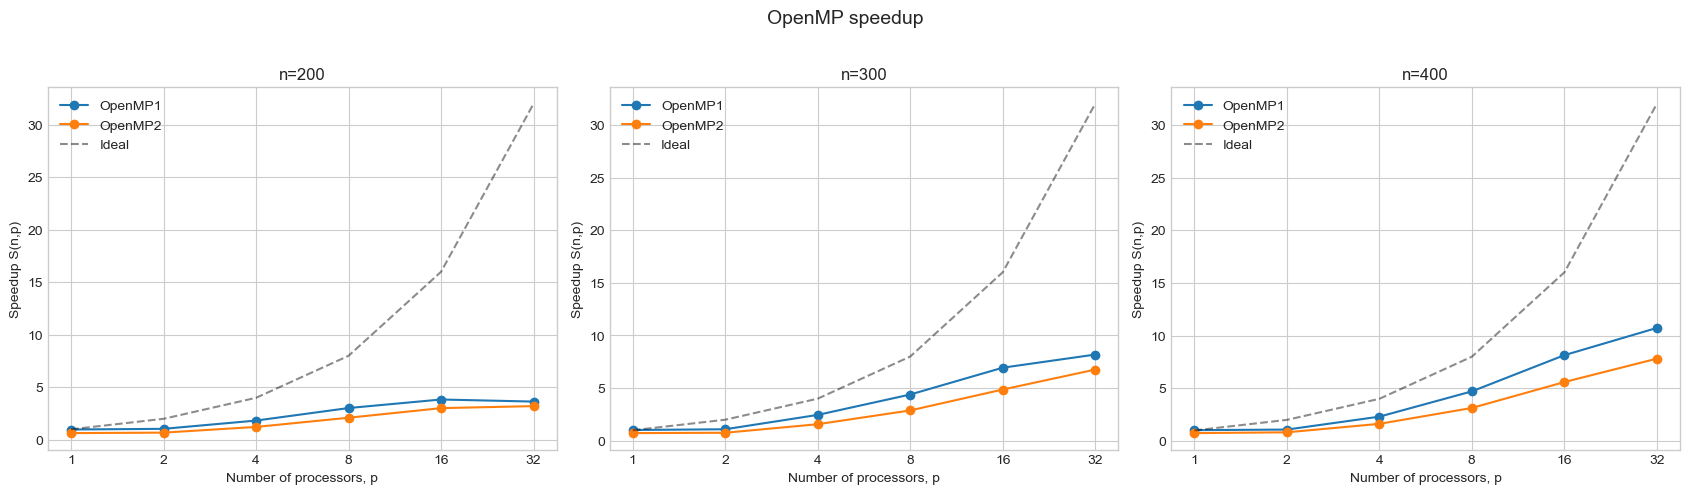

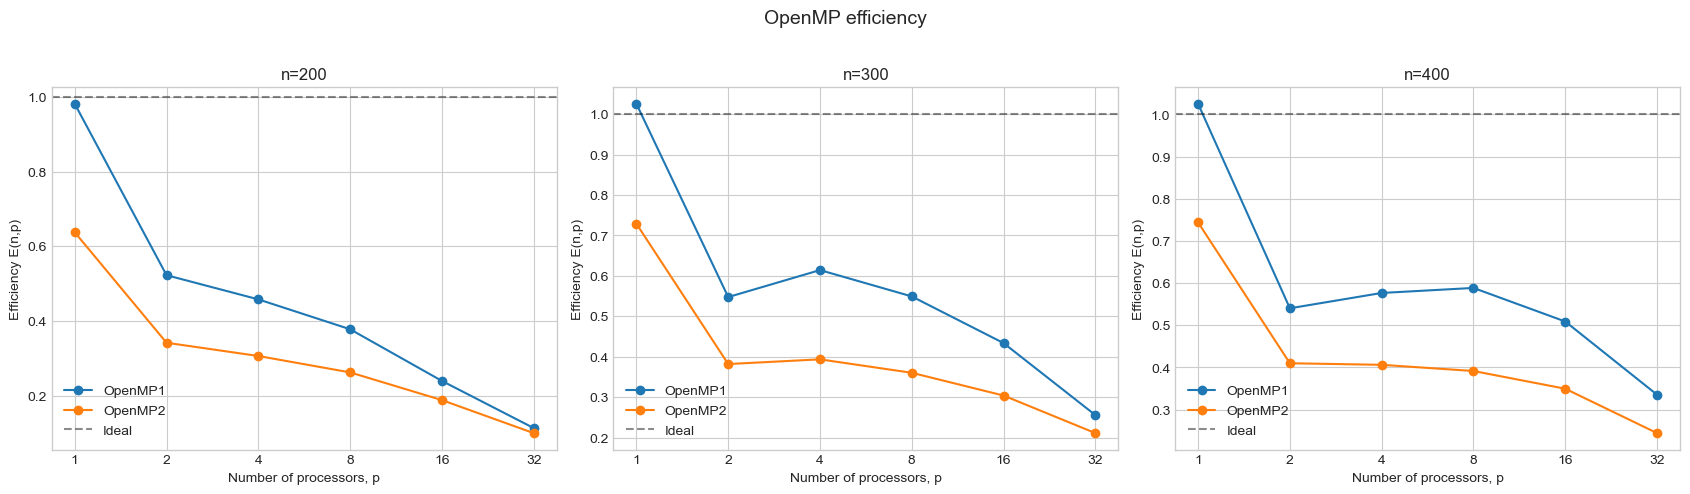

In [6]:
openmp_versions = ["OpenMP1", "OpenMP2"]
plot_version_comparison(
    parallel_df,
    openmp_versions,
    "average_time",
    "OpenMP average execution time",
    "Average execution time (s)",
)
plot_version_comparison(
    parallel_df,
    openmp_versions,
    "speedup",
    "OpenMP speedup",
    "Speedup S(n,p)",
    ideal="speedup",
)
plot_version_comparison(
    parallel_df,
    openmp_versions,
    "efficiency",
    "OpenMP efficiency",
    "Efficiency E(n,p)",
    ideal="efficiency",
)


## MPI plots

The figures compare MPI1, MPI2, and MPI3 using average execution time, speedup, and efficiency.

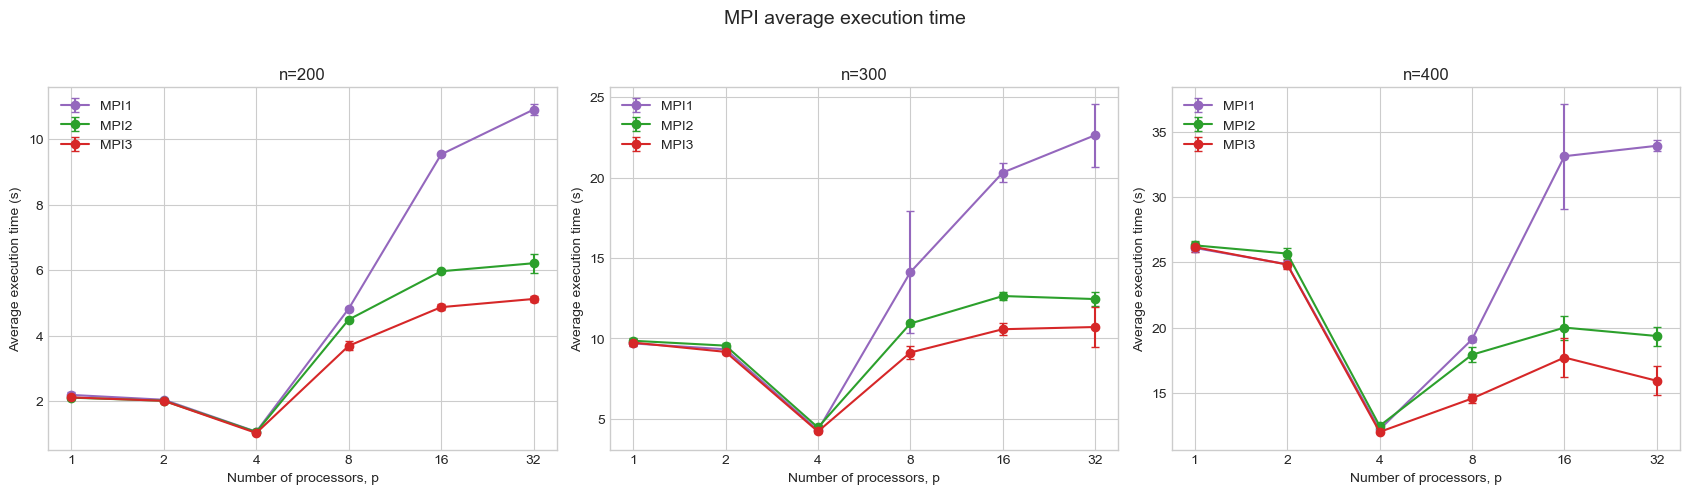

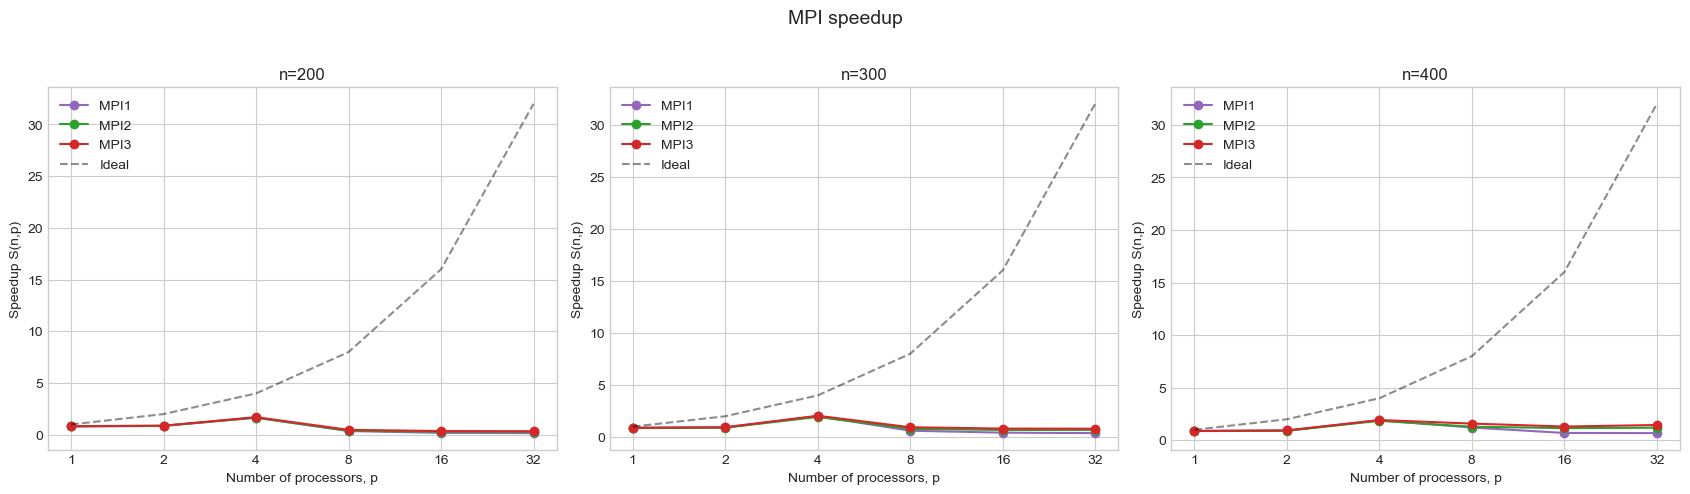

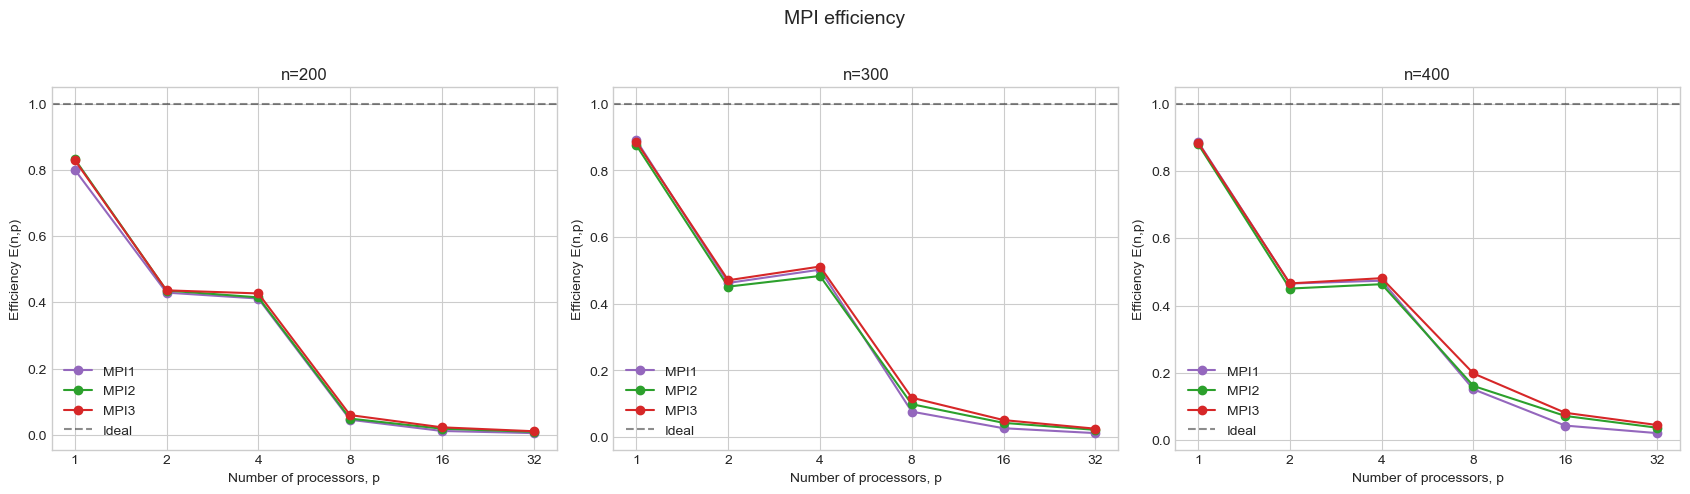

In [7]:
mpi_versions = ["MPI1", "MPI2", "MPI3"]
plot_version_comparison(
    parallel_df,
    mpi_versions,
    "average_time",
    "MPI average execution time",
    "Average execution time (s)",
)
plot_version_comparison(
    parallel_df,
    mpi_versions,
    "speedup",
    "MPI speedup",
    "Speedup S(n,p)",
    ideal="speedup",
)
plot_version_comparison(
    parallel_df,
    mpi_versions,
    "efficiency",
    "MPI efficiency",
    "Efficiency E(n,p)",
    ideal="efficiency",
)


## Overall execution-time comparison

The dashed line is the updated sequential baseline for each problem size.

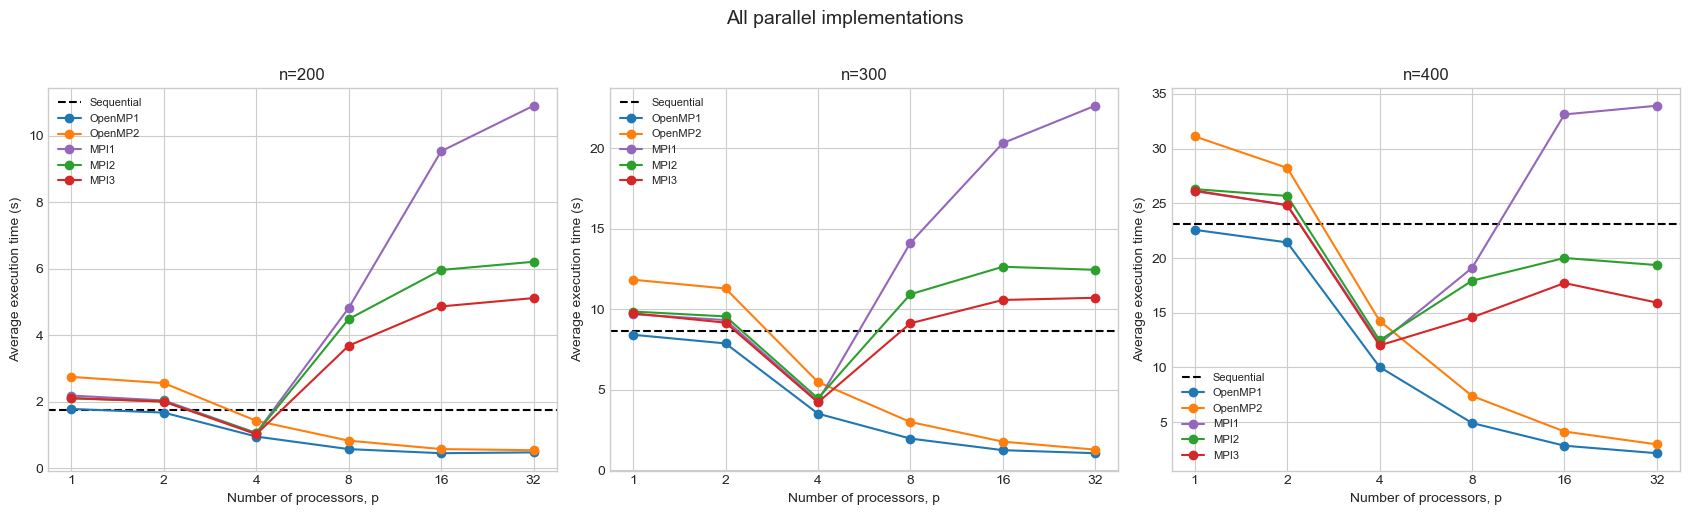

In [8]:
fig, axes = plt.subplots(1, len(N_VALUES), figsize=(17, 5.0), sharey=False)
for ax, n in zip(axes, N_VALUES):
    seq_time = seq_df.loc[seq_df["n"] == n, "average_time"].iloc[0]
    ax.axhline(seq_time, color="black", linestyle="--", label="Sequential")
    for version in VERSION_DESCRIPTIONS:
        subset = results[version][results[version]["n"] == n].sort_values("p")
        ax.plot(
            subset["p"],
            subset["average_time"],
            marker="o",
            color=COLORS[version],
            label=version,
        )
    configure_processor_axis(ax, PROCESSOR_VALUES)
    ax.set_title(f"n={n}")
    ax.set_ylabel("Average execution time (s)")
    ax.legend(fontsize=8)

fig.suptitle("All parallel implementations", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()
